# Results figure — manually verified match (n = 15)

Writes `results_match_accuracy.png` and `.pdf` in this folder.

| | Full | Partial | No match |
|---|---:|---:|---:|
| Diagnosis | 8/15 (53.3%) | 3/15 (20.0%) | 4/15 (26.7%) |
| ICD codes | 5/15 (33.3%) | 5/15 (33.3%) | 5/15 (33.3%) |

ICD codes full + partial = 10/15 (66.7%).

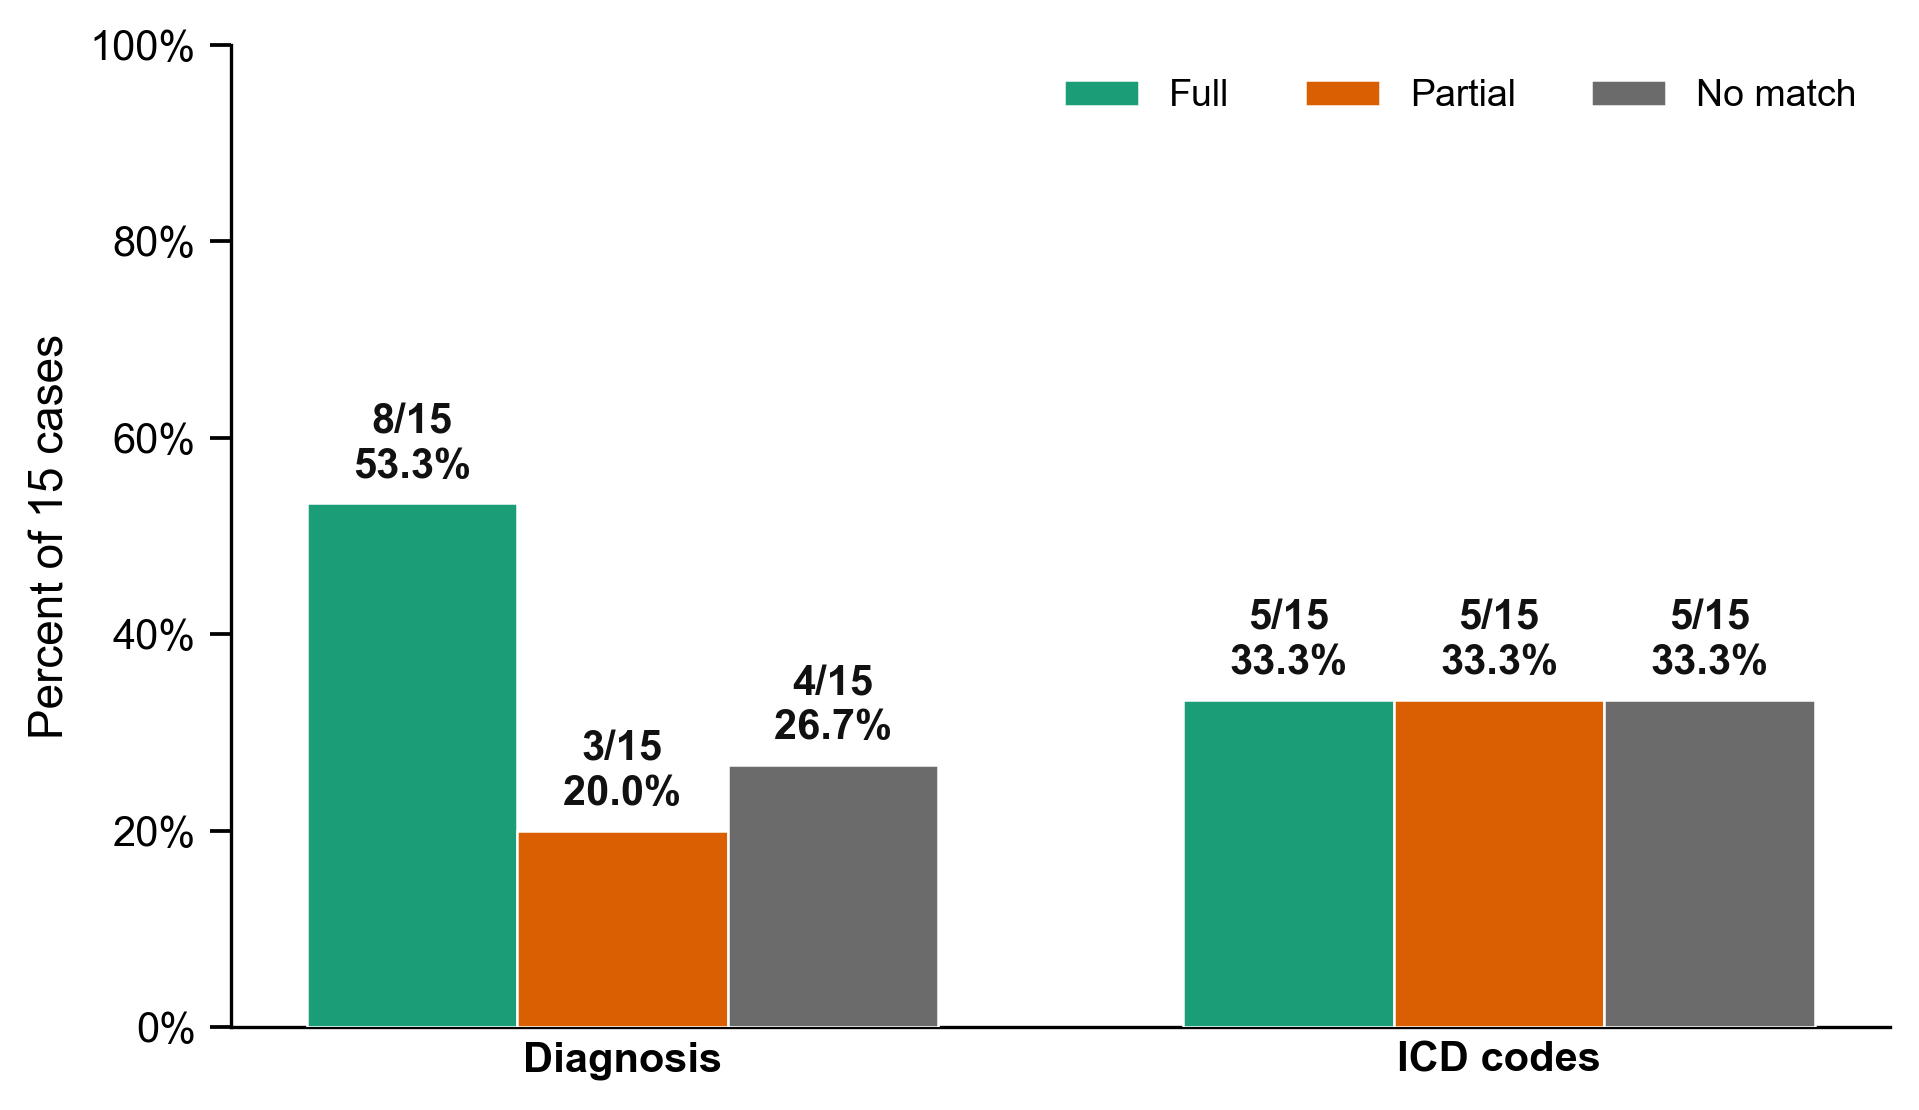

Wrote /Users/narenkhatwani/GitHub/ai-agents-for-clinical-coding/orbit_dx_accuracy/results_match_accuracy.png
Wrote /Users/narenkhatwani/GitHub/ai-agents-for-clinical-coding/orbit_dx_accuracy/results_match_accuracy.pdf


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

OUT_DIR = Path.cwd()
if not (OUT_DIR / "icd_match.csv").exists():
    OUT_DIR = Path("/Users/narenkhatwani/GitHub/ai-agents-for-clinical-coding/orbit_dx_accuracy")

N = 15
counts = {
    "Diagnosis": {"Full": 8, "Partial": 3, "No match": 4},
    "ICD codes": {"Full": 5, "Partial": 5, "No match": 5},
}
categories = ["Diagnosis", "ICD codes"]
series = ["Full", "Partial", "No match"]
colors = {"Full": "#1b9e77", "Partial": "#d95f02", "No match": "#6b6b6b"}


def pct(k: int) -> float:
    return 100.0 * k / N


plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "legend.fontsize": 9,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

x = np.arange(len(categories))
width = 0.24
offsets = np.linspace(-(width), width, len(series))

fig, ax = plt.subplots(figsize=(6.5, 3.8), dpi=300)

for off, label in zip(offsets, series):
    vals = [pct(counts[cat][label]) for cat in categories]
    ks = [counts[cat][label] for cat in categories]
    bars = ax.bar(
        x + off,
        vals,
        width,
        label=label,
        color=colors[label],
        edgecolor="white",
        linewidth=0.6,
        zorder=3,
    )
    for bar, k, v in zip(bars, ks, vals):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1.8,
            f"{k}/{N}\n{v:.1f}%",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            color="#111111",
        )

ax.set_ylabel("Percent of 15 cases")
ax.set_ylim(0, 100)
ax.set_yticks(np.arange(0, 101, 20))
ax.set_yticklabels([f"{t}%" for t in range(0, 101, 20)])
ax.set_xticks(x)
ax.set_xticklabels(categories, fontweight="bold")
ax.set_title("")
ax.grid(False)
ax.xaxis.grid(False)
ax.yaxis.grid(False)
ax.tick_params(axis="y", length=5, width=0.9, labelsize=10)
ax.tick_params(axis="x", length=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, ncol=3, loc="upper right")

fig.tight_layout()

png = OUT_DIR / "results_match_accuracy.png"
pdf = OUT_DIR / "results_match_accuracy.pdf"
fig.savefig(png, bbox_inches="tight")
fig.savefig(pdf, bbox_inches="tight")
plt.show()
print(f"Wrote {png}")
print(f"Wrote {pdf}")